![image.png](https://i.imgur.com/a3uAqnb.png)

# Knowledge Graphs for Questions That Span Several Pages

- **Dataset**: 38 pages of [GitLab's public handbook](https://handbook.gitlab.com) at a fixed commit (CC BY-SA 4.0), the same pages as the other RAG labs
- **Task**: answer questions that link or collect facts from several benefits pages (UK, Ireland, the Netherlands, the US, Australia, Canada)
- **Model**: [Qwen3.5-4B](https://huggingface.co/Qwen/Qwen3.5-4B) to extract facts, write queries and answer; [multilingual-e5-base](https://huggingface.co/intfloat/multilingual-e5-base) to search
- **Runtime**: Colab T4 GPU, about 25 minutes

In this lab, we will:

- see which questions a top-5 chunk search cannot answer, even when every fact is in the documents
- extract facts as (country, relation, value) triples with the LLM and a fixed list of relations
- store them as a graph and answer a two-step question by walking it
- answer from the extracted facts, and let the model write SQL over them
- compare chunks, facts and SQL on the same ten questions

## Knowledge graphs in brief

A knowledge graph stores facts as **triples** $(s, r, o)$: a subject $s$, a relation $r$ and an object $o$, such as
(Ireland, medical insurer, VHI). Subjects and objects are nodes; relations are typed edges.

Chunk search answers a question from the $k$ passages most similar to it. That fails when the answer needs:

- **a chain of facts**: "the pension in the country where VHI is the insurer" needs VHI $\to$ Ireland $\to$ pension;
- **the same fact from many pages**: "the insurer in each of four countries" needs four pages in the top $k$ at once.

A graph built once from the documents turns both into look-ups.

## Setup

In Google Colab, select **Runtime > Change runtime type > T4 GPU**, then run the cells from top to bottom. The next
cell installs the one library Colab lacks (BM25 keyword search).

In [1]:
%pip install -q rank_bm25

In [2]:
import concurrent.futures as cf
import json
import random
import re
import sqlite3
import time
from urllib.parse import quote

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
import torch
from transformers import AutoModelForImageTextToText, AutoTokenizer

In [3]:
SEED = 42
MODEL_ID = "Qwen/Qwen3.5-4B"
EMBED_ID = "intfloat/multilingual-e5-base"
TOP_K = 5                 # chunks given to the model in the chunk-search baseline
MAX_NEW_TOKENS = 200      # per extraction or answer
BATCH_SIZE = 8            # prompts per generate() call

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 120)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
else:
    print("No GPU found, so generation will be slow. In Colab: Runtime > Change runtime type > T4 GPU.")

PyTorch 2.14.1+cu130 | device: cuda
GPU: Tesla T4 (15.6 GB)


## 1. Documents

- **Source**: GitLab's handbook repository, fetched through the GitLab API at one pinned commit, so everyone reads the same text
- **Content**: 38 pages of HR, benefits, finance, security and legal policy
- **Licence**: CC BY-SA 4.0
- **What we use**: all 38 pages for search; the six country benefits pages for the graph

The cleaning keeps the words and headings and drops templates, HTML tags and link targets.

In [4]:
API = "https://gitlab.com/api/v4/projects/gitlab-com%2Fcontent-sites%2Fhandbook/repository"
REF = "df66e66b937d38c1ed4e3dd452927ddf01be58b0"
BENEFITS = {   # page -> the country every fact on it is about
    "total-rewards/benefits/general-and-entity-benefits/ltd-benefits-uk.md": "UK",
    "total-rewards/benefits/general-and-entity-benefits/gitlab-ireland-ltd.md": "Ireland",
    "total-rewards/benefits/general-and-entity-benefits/bv-benefits-netherlands.md": "Netherlands",
    "total-rewards/benefits/general-and-entity-benefits/inc-benefits-us/_index.md": "US",
    "total-rewards/benefits/general-and-entity-benefits/pty-benefits-australia.md": "Australia",
    "total-rewards/benefits/general-and-entity-benefits/canada-corp-benefits.md": "Canada",
}
OTHER_PAGES = """people-group/time-off-and-absence/time-off-types.md people-group/time-off-and-absence/leave-types.md
people-group/anti-harassment.md people-group/contracts-probation-periods.md people-group/acceptable-use-policy.md
people-group/general-onboarding/_index.md people-group/offboarding/faq.md people-policies/inc-usa.md
people-policies/leave-of-absence/us.md people-policies/ireland-ltd/right-to-disconnect-policy.md
people-policies/france-sas/remote-work-charter.md total-rewards/benefits/_index.md
total-rewards/benefits/parental-leave-toolkit.md total-rewards/compensation/_index.md total-rewards/stock-options.md
finance/expenses.md finance/spending-company-money.md finance/procurement/individual-use-software.md
finance/accounts-payable/corp-credit-cards.md security/policies_and_standards/password-standard.md
security/policies_and_standards/data-classification-standard.md
security/policies_and_standards/physical-security-standard-for-company-assets.md
security/policies_and_standards/records-retention-deletion.md security/policies_and_standards/token-management-standard.md
legal/anti-corruption-policy.md legal/anti-fraud-policy.md legal/anti-retaliation-policy.md
legal/policies/gifts-contributions.md legal/acceptable-use-policy.md business-technology/_index.md
communication/confidentiality-levels.md hiring/referral-process.md""".split()


def fetch(page):
    raw = requests.get(f"{API}/files/{quote('content/handbook/' + page, safe='')}/raw", params={"ref": REF}, timeout=60).text
    front, body = raw.split("\n---\n", 1)
    body = re.sub(r"\{\{[<%].*?[>%]\}\}|<!--.*?-->|<[^>\n]+>", "", body, flags=re.S)   # templates, comments, tags
    body = re.sub(r"\[([^\]]+)\]\([^)]*\)", r"\1", body)                                 # [text](url) -> text
    title = re.search(r'^title:\s*"?(.*?)"?\s*$', front, re.M).group(1)
    return {"page": page, "title": title, "text": re.sub(r"[ \t]+", " ", body).strip()}


with cf.ThreadPoolExecutor(8) as pool:
    docs = list(pool.map(fetch, list(BENEFITS) + OTHER_PAGES))
print(len(docs), "pages,", sum(len(d["text"].split()) for d in docs), "words")

38 pages, 98952 words


Chunks follow the page structure: each starts at a heading and keeps it, and long sections are cut at about 1,200
characters. Every chunk carries its page and title.

In [5]:
def chunk_sections(text, max_chars=1200):
    out = []
    for section in re.split(r"\n(?=#{1,4} )", text):
        head = section.split("\n")[0] if section.startswith("#") else ""
        piece = ""
        for word in section.split():
            if len(piece) + len(word) > max_chars and piece:
                out.append(piece.strip()); piece = head + "\n" if head else ""
            piece += word + " "
        out.append(piece.strip())
    return [p for p in out if len(p) > 60]


chunks = [{"page": d["page"], "title": d["title"], "text": c} for d in docs for c in chunk_sections(d["text"])]
print(len(chunks), "chunks;", sum(c["page"] in BENEFITS for c in chunks), "from the six benefits pages")

970 chunks; 181 from the six benefits pages


## 2. The questions

Five questions follow a chain through one country (find the country from one fact, then read another fact), and
five collect the same kind of fact from several countries. Each answer lists the strings it must contain.

In [6]:
QUESTIONS = [
    ("Up to what percentage does GitLab match pension contributions in the country where VHI provides medical insurance?", ["5%"]),
    ("Who runs the pension plan in the country where team members get a EUR 150 monthly medical allowance?", ["ASR"]),
    ("Which insurer provides health cover in the country where GitLab's retirement contribution is 12% of salary?", ["BUPA"]),
    ("What is the life insurance multiple of salary in the country whose pension is run by Scottish Widows?", ["4x"]),
    ("How many vacation days per year are guaranteed in the country whose pension plan is run by ASR?", ["20"]),
    ("Which companies provide private medical insurance in the UK, Ireland, Australia and Canada?", ["AXA PPP", "VHI", "BUPA", "ManuLife"]),
    ("Which companies run the pension or retirement plans in the UK, Ireland, the Netherlands and Canada?", ["Scottish Widows", "Aviva", "ASR", "Canada Life"]),
    ("What does GitLab contribute to retirement in the UK, the Netherlands and Australia?", ["4%", "3%", "12%"]),
    ("In which of the UK, Ireland, the Netherlands, Australia and Canada does GitLab contribute the largest share of salary to retirement?", ["Australia"]),
    ("What share of salary does disability or income protection insurance replace in the UK, Ireland, Canada and the US?", ["66%", "66.67%", "66.7%"]),
]


def correct(reply, answers):
    """True when every expected string appears in the reply (case-insensitive)."""
    text = reply.lower().replace(",", "")
    return all(a.lower().replace(",", "") in text for a in answers)

## 3. The model

`chat_batch()` sends several conversations at once and returns the replies, with thinking turned off.

In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=DTYPE, device_map="auto").eval()


def chat_batch(conversations, max_new_tokens=MAX_NEW_TOKENS):
    texts = [tok.apply_chat_template(c, tokenize=False, add_generation_prompt=True, enable_thinking=False)
             for c in conversations]
    replies = []
    for i in range(0, len(texts), BATCH_SIZE):
        enc = tok(texts[i:i + BATCH_SIZE], return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        replies += tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return [r.strip() for r in replies]

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

## 4. Baseline: chunk search

Hybrid search: BM25 and dense rankings merged by reciprocal rank fusion. The model answers from the top `TOP_K`
chunks, citing them. We also record whether the chunks cover every page the answer needs.

In [8]:
embedder = SentenceTransformer(EMBED_ID, device=DEVICE)
chunk_vecs = embedder.encode(["passage: " + c["title"] + "\n" + c["text"] for c in chunks], normalize_embeddings=True,
                             batch_size=32, show_progress_bar=False)
bm25 = BM25Okapi([re.findall(r"\w+", (c["title"] + " " + c["text"]).lower()) for c in chunks])


def search(question, k=TOP_K):
    dense = np.argsort(-(chunk_vecs @ embedder.encode(["query: " + question], normalize_embeddings=True)[0]))[:50]
    sparse = np.argsort(-bm25.get_scores(re.findall(r"\w+", question.lower())))[:50]
    score = {}
    for ranking in (dense, sparse):
        for rank, i in enumerate(ranking, start=1):
            score[int(i)] = score.get(int(i), 0) + 1 / (60 + rank)
    return sorted(score, key=score.get, reverse=True)[:k]


SYSTEM_RAG = ("Answer the question using only the numbered passages from the GitLab handbook. Cite passages like [1]. "
              "If they do not contain the answer, say so. Answer in one or two sentences.")


def rag_prompt(question, ids):
    passages = "\n\n".join(f"[{n}] ({chunks[i]['title']}) {chunks[i]['text']}" for n, i in enumerate(ids, 1))
    return [{"role": "system", "content": SYSTEM_RAG},
            {"role": "user", "content": f"Passages:\n{passages}\n\nQuestion: {question}"}]


start = time.time()
retrieved = [search(q) for q, _ in QUESTIONS]
chunk_replies = chat_batch([rag_prompt(q, ids) for (q, _), ids in zip(QUESTIONS, retrieved)])
baseline = pd.DataFrame({"question": [q for q, _ in QUESTIONS],
                         "benefits pages in top k": [len({chunks[i]["page"] for i in ids} & set(BENEFITS)) for ids in retrieved],
                         "correct": [correct(r, a) for r, (_, a) in zip(chunk_replies, QUESTIONS)]})
print(f"chunk search: {baseline['correct'].sum()} of {len(QUESTIONS)} correct ({time.time() - start:.0f} s)")
baseline

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


chunk search: 4 of 10 correct (24 s)


,question,benefits pages in top k,correct
0,Up to what percentage does GitLab match pension contributions in the country where VHI provides medical insurance?,2,True
1,Who runs the pension plan in the country where team members get a EUR 150 monthly medical allowance?,3,False
2,Which insurer provides health cover in the country where GitLab's retirement contribution is 12% of salary?,2,False
3,What is the life insurance multiple of salary in the country whose pension is run by Scottish Widows?,1,False
4,How many vacation days per year are guaranteed in the country whose pension plan is run by ASR?,3,True
5,"Which companies provide private medical insurance in the UK, Ireland, Australia and Canada?",3,False
6,"Which companies run the pension or retirement plans in the UK, Ireland, the Netherlands and Canada?",3,False
7,"What does GitLab contribute to retirement in the UK, the Netherlands and Australia?",3,True
8,"In which of the UK, Ireland, the Netherlands, Australia and Canada does GitLab contribute the largest share of salar...",3,True
9,"What share of salary does disability or income protection insurance replace in the UK, Ireland, Canada and the US?",2,False


**What to look for.** Count how many benefits pages reach the top 5 for the questions about four or five countries.
A question that names several countries pulls chunks that mention several countries, not one chunk per country.

## 5. Extract facts with a fixed schema

The model reads each chunk of the six benefits pages and lists only facts for eight relations we fix in advance.
A fixed list keeps one name per edge type ("medical insurer", never also "health provider"). The subject is not
asked for: it comes from the page's metadata, since each benefits page is about one country.

In [9]:
RELATIONS = ["medical insurer", "pension provider", "employer retirement contribution", "life insurance",
             "disability or income protection", "vacation days", "medical allowance", "parental leave"]
EXTRACT_PROMPT = """Read this passage from the {country} benefits page of a company handbook. List the facts it states about
these relations only: {relations}.
Return JSON only: a list of objects {{"relation": "...", "value": "..."}}, with the value copied briefly from the passage
(a company name, a percentage, an amount or a duration). Return [] if the passage states none of them.

Passage: {passage}"""


def parse_facts(reply):
    match = re.search(r"\[.*\]", reply, re.S)
    try:
        items = json.loads(match.group(0)) if match else []
    except json.JSONDecodeError:
        return []
    return [i for i in items if isinstance(i, dict) and i.get("relation") in RELATIONS and i.get("value")]


benefit_chunks = [c for c in chunks if c["page"] in BENEFITS]
start = time.time()
replies = chat_batch([[{"role": "user", "content": EXTRACT_PROMPT.format(country=BENEFITS[c["page"]],
                       relations="; ".join(RELATIONS), passage=c["text"])}] for c in benefit_chunks])
facts = pd.DataFrame([(BENEFITS[c["page"]], f["relation"], str(f["value"]))
                      for c, r in zip(benefit_chunks, replies) for f in parse_facts(r)],
                     columns=["country", "relation", "value"]).drop_duplicates()
print(f"{len(facts)} facts from {len(benefit_chunks)} chunks in {time.time() - start:.0f} s")
facts.sort_values(["relation", "country"]).head(30)

46 facts from 181 chunks in 97 s


,country,relation,value
44,Australia,disability or income protection,None
19,Ireland,disability or income protection,none
26,Ireland,disability or income protection,66% of base salary
27,Ireland,disability or income protection,age 65
28,Ireland,disability or income protection,13-week deferred period
4,UK,disability or income protection,66% of your base salary
38,US,disability or income protection,66.7%
39,US,disability or income protection,26 weeks
42,Australia,employer retirement contribution,None
48,Australia,employer retirement contribution,12%


**Check a sample by hand.** Pick five rows and find each value on its page. Extraction errors become graph errors,
and no later step can see them.

In [10]:
facts.groupby("relation").size().rename("facts").to_frame()

,facts
relation,
disability or income protection,8
employer retirement contribution,11
life insurance,6
medical allowance,5
medical insurer,5
parental leave,5
pension provider,3
vacation days,3


## 6. The graph, and a walk through it

Countries and values become nodes; each fact is a typed edge. A two-step question is a walk: find the country
linked to a known value, then follow another edge from it.

42 nodes, 46 edges


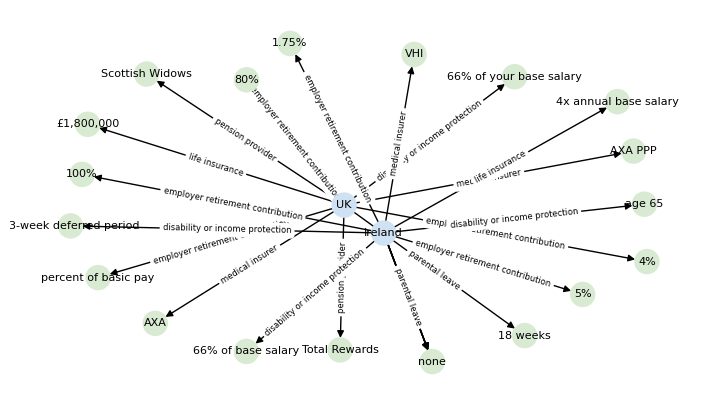

In [11]:
G = nx.MultiDiGraph()
for row in facts.itertuples():
    G.add_edge(row.country, row.value, relation=row.relation)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

shown = [c for c in ("Ireland", "UK") if c in G]          # two countries, to keep the drawing readable
sub = G.subgraph(shown + [v for c in shown for v in G.successors(c)])
plt.figure(figsize=(9, 5))
pos = nx.spring_layout(sub, seed=SEED)
nx.draw_networkx(sub, pos, node_color=["#cfe2f3" if n in BENEFITS.values() else "#d9ead3" for n in sub], font_size=8)
nx.draw_networkx_edge_labels(sub, pos, edge_labels={(u, v): d["relation"] for u, v, d in sub.edges(data=True)}, font_size=6)
plt.axis("off")
plt.show()

In [12]:
def walk(known_value, then_relation):
    """Countries with an edge to a value containing `known_value`, then their `then_relation` values."""
    countries = {u for u, v in G.edges() if known_value.lower() in v.lower()}
    return {c: [v for _, v, d in G.out_edges(c, data=True) if d["relation"] == then_relation] for c in countries}


walk("VHI", "employer retirement contribution")

{'Ireland': ['100%', '5%', '1.75%']}

## 7. Answer from the facts

The whole graph is small enough to fit in the prompt as a list of triples. The model answers from it, the same way it
answered from chunks.

In [13]:
fact_lines = "\n".join(f"({r.country}, {r.relation}, {r.value})" for r in facts.itertuples())
print(len(tok(fact_lines).input_ids), "tokens for all facts")

SYSTEM_FACTS = ("Answer the question using only the facts listed, written as (country, relation, value). "
                "Answer in one or two sentences.")
fact_replies = chat_batch([[{"role": "system", "content": SYSTEM_FACTS},
                            {"role": "user", "content": f"Facts:\n{fact_lines}\n\nQuestion: {q}"}] for q, _ in QUESTIONS])
baseline["facts correct"] = [correct(r, a) for r, (_, a) in zip(fact_replies, QUESTIONS)]
print(f"facts: {baseline['facts correct'].sum()} of {len(QUESTIONS)} correct")

604 tokens for all facts
facts: 3 of 10 correct


## 8. Text-to-SQL: the model writes the query

For counts, filters and "every country", the facts can live in a table. The model reads the schema and writes one
`SELECT`; the database runs it. The connection is read-only and the query must start with `SELECT`.

In [14]:
facts.to_sql("facts", sqlite3.connect("facts.db"), index=False, if_exists="replace")
db = sqlite3.connect("file:facts.db?mode=ro", uri=True)

SQL_PROMPT = ("Table facts(country, relation, value). Countries: UK, Ireland, Netherlands, US, Australia, Canada. "
              "Relations: {relations}. Write one SQLite SELECT query that returns the rows needed to answer: {question}\n"
              "Return the SQL only.")


def run_sql(question):
    sql = chat_batch([[{"role": "user", "content": SQL_PROMPT.format(relations="; ".join(RELATIONS), question=question)}]],
                     max_new_tokens=120)[0]
    sql = re.sub(r"^```(sql)?|```$", "", sql.strip(), flags=re.M).strip()
    if not sql.upper().startswith("SELECT"):
        return sql, []
    try:
        return sql, db.execute(sql).fetchmany(50)
    except sqlite3.Error as error:
        return sql, [("error", str(error))]


sql, rows = run_sql(QUESTIONS[5][0])
print(sql)
rows

SELECT country, relation, value
FROM table_facts
WHERE country IN ('UK', 'Ireland', 'Australia', 'Canada')
  AND relation = 'medical insurer';


[('error', 'no such table: table_facts')]

Run every question through SQL, then let the model phrase an answer from the rows it got back.

In [15]:
sql_results = [run_sql(q) for q, _ in QUESTIONS]
sql_replies = chat_batch([[{"role": "user", "content": f"Question: {q}\nRows from the database: {rows}\n"
                            "Answer the question from these rows only, in one sentence."}]
                          for (q, _), (_, rows) in zip(QUESTIONS, sql_results)])
baseline["SQL correct"] = [correct(r, a) for r, (_, a) in zip(sql_replies, QUESTIONS)]
baseline[["question", "benefits pages in top k", "correct", "facts correct", "SQL correct"]]

,question,benefits pages in top k,correct,facts correct,SQL correct
0,Up to what percentage does GitLab match pension contributions in the country where VHI provides medical insurance?,2,True,False,False
1,Who runs the pension plan in the country where team members get a EUR 150 monthly medical allowance?,3,False,True,False
2,Which insurer provides health cover in the country where GitLab's retirement contribution is 12% of salary?,2,False,True,False
3,What is the life insurance multiple of salary in the country whose pension is run by Scottish Widows?,1,False,False,False
4,How many vacation days per year are guaranteed in the country whose pension plan is run by ASR?,3,True,True,False
5,"Which companies provide private medical insurance in the UK, Ireland, Australia and Canada?",3,False,False,False
6,"Which companies run the pension or retirement plans in the UK, Ireland, the Netherlands and Canada?",3,False,False,False
7,"What does GitLab contribute to retirement in the UK, the Netherlands and Australia?",3,True,False,False
8,"In which of the UK, Ireland, the Netherlands, Australia and Canada does GitLab contribute the largest share of salar...",3,True,False,True
9,"What share of salary does disability or income protection insurance replace in the UK, Ireland, Canada and the US?",2,False,False,False


**What to look for.** Chunk search fails most on the questions about four or five countries, where the top 5 cannot
hold every page. The facts answer them from one small list. SQL is exact when the query is right, and wrong with
full confidence when it filters on a relation name the table does not use: read the queries.

## Summary

- Top-$k$ chunk search fails on questions that need several pages at once, even when every fact is in the documents.
- An LLM with a fixed list of relations turns passages into triples; the subject can come from the page's metadata.
- A graph turns a two-step question into a walk, and a list of facts answers "for every country" questions in one prompt.
- Text-to-SQL is exact when the model writes the right query; a read-only connection and a check that it is a `SELECT` keep it safe.

## Exercises

1. Set `TOP_K` to 10. How many benefits pages reach the prompt now, and how many chunk answers become correct?
2. Remove the relation list from `EXTRACT_PROMPT` and ask for any facts as (subject, relation, object). How many different relation names do you get for the medical insurer?
3. Add the relation `"waiting period"` to `RELATIONS`, re-extract, and ask: "Which country has a 90-day waiting period for long-term disability?"
4. Write two questions of your own that need two pages, and test all three methods on them.

## Further Reading

- [Edge et al., 2024. From Local to Global: A Graph RAG Approach to Query-Focused Summarization](https://arxiv.org/abs/2404.16130)
- [Hogan et al., 2021. Knowledge Graphs](https://arxiv.org/abs/2003.02320)
- [NetworkX documentation](https://networkx.org/documentation/stable/)

### Contributed by: Yazen Shaebi